# METALYX — Controlled Comparison: B-spline vs SimCLR vs Feature Fusion

**Purpose:** evaluate three feature pipelines on exactly the same official NEU-DET training and validation images:

1. **B-spline-only:** 10 handcrafted geometric descriptors.
2. **SimCLR-only:** 512-dimensional ResNet-18 encoder features.
3. **SimCLR + B-spline:** concatenated 522-dimensional features.

This notebook is designed to make the comparison systematic and reproducible. It does **not** retrain SimCLR; it loads the existing checkpoint and trains the same downstream classifier for each feature set.

## Evaluation protocol

- Train the downstream classifier on the official `train/images` directory (expected: 1,440 images).
- Evaluate on the official `validation/images` directory (expected: 360 images).
- Use the same class mapping, exact image lists, `StandardScaler`, and Logistic Regression settings for all three methods.
- Extract SimCLR embeddings using `Resize((224, 224))` + `ToTensor()` **without ImageNet normalization**, matching the SimCLR training pipeline supplied for review.
- Save metrics, per-class reports, predictions, confusion matrices, and a run configuration to Google Drive.

**Important limitations:** the official validation set is the evaluation set for this comparison, not an untouched independent test set. If it has already been used repeatedly to select methods or settings, describe results as validation performance. This notebook can only establish the checkpoint path and loading compatibility; keep a record of which training run produced the checkpoint and verify it was trained without validation images.

## 1. Mount Google Drive and set paths

Edit `DATA_ROOT`, `CHECKPOINT_PATH`, or `OUTPUT_DIR` if your Google Drive folders differ. This notebook expects six class subfolders inside each `images` directory.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path
import os, json, random, time, platform, warnings
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.interpolate import splprep, splev
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', DEVICE)
print('PyTorch:', torch.__version__)
print('OpenCV:', cv2.__version__)

Device: cuda
PyTorch: 2.11.0+cu130
OpenCV: 4.14.0


In [3]:
DATA_ROOT = Path('/content/drive/MyDrive/NEU-DET')
TRAIN_IMAGE_DIR = DATA_ROOT / 'train' / 'images'
VAL_IMAGE_DIR = DATA_ROOT / 'validation' / 'images'

CHECKPOINT_PATH = Path('/content/drive/MyDrive/METALYX/models/simclr_resnet18.pth')
OUTPUT_DIR = Path('/content/drive/MyDrive/METALYX/fair_comparison_results')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = [
    'crazing',
    'inclusion',
    'patches',
    'pitted_surface',
    'rolled-in_scale',
    'scratches'
]
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.tif', '.tiff'}

for name, path in {
    'Training images': TRAIN_IMAGE_DIR,
    'Validation images': VAL_IMAGE_DIR,
    'SimCLR checkpoint': CHECKPOINT_PATH
}.items():
    print(f'{name}: {path} | exists={path.exists()}')

if not TRAIN_IMAGE_DIR.is_dir():
    raise FileNotFoundError(f'Training image directory not found: {TRAIN_IMAGE_DIR}')
if not VAL_IMAGE_DIR.is_dir():
    raise FileNotFoundError(f'Validation image directory not found: {VAL_IMAGE_DIR}')
if not CHECKPOINT_PATH.is_file():
    raise FileNotFoundError(f'SimCLR checkpoint not found: {CHECKPOINT_PATH}')

Training images: /content/drive/MyDrive/NEU-DET/train/images | exists=True
Validation images: /content/drive/MyDrive/NEU-DET/validation/images | exists=True
SimCLR checkpoint: /content/drive/MyDrive/METALYX/models/simclr_resnet18.pth | exists=True


## 2. Collect image paths and verify the official split

Labels are assigned from the folder names using one fixed class mapping. The exact ordered image lists will be saved with the results.

In [4]:
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASS_NAMES)}

def collect_paths_and_labels(root_dir):
    paths, labels = [], []
    for class_name in CLASS_NAMES:
        class_dir = root_dir / class_name
        if not class_dir.is_dir():
            raise FileNotFoundError(f'Missing class folder: {class_dir}')
        class_paths = sorted(
            p for p in class_dir.iterdir()
            if p.is_file() and p.suffix.lower() in IMAGE_EXTS
        )
        paths.extend([str(p.resolve()) for p in class_paths])
        labels.extend([CLASS_TO_IDX[class_name]] * len(class_paths))
    return np.asarray(paths), np.asarray(labels, dtype=np.int64)

train_paths, y_train = collect_paths_and_labels(TRAIN_IMAGE_DIR)
val_paths, y_val = collect_paths_and_labels(VAL_IMAGE_DIR)

print('Training images:', len(train_paths))
print('Validation images:', len(val_paths))
print('Training class counts:')
print(pd.Series([CLASS_NAMES[i] for i in y_train]).value_counts().reindex(CLASS_NAMES))
print('\nValidation class counts:')
print(pd.Series([CLASS_NAMES[i] for i in y_val]).value_counts().reindex(CLASS_NAMES))

if len(train_paths) != 1440 or len(val_paths) != 360:
    warnings.warn(
        f'Expected 1440 train and 360 validation images; found {len(train_paths)} and {len(val_paths)}. '
        'Confirm the dataset version and directory contents before reporting results.'
    )

overlap = set(train_paths).intersection(set(val_paths))
if overlap:
    raise ValueError(f'Found {len(overlap)} paths shared between train and validation directories.')

for split_name, labels in [('train', y_train), ('validation', y_val)]:
    missing = [CLASS_NAMES[i] for i in range(len(CLASS_NAMES)) if np.sum(labels == i) == 0]
    if missing:
        raise ValueError(f'{split_name} split has no images for classes: {missing}')

print('Exact train/validation path overlap: 0')

Training images: 1440
Validation images: 360
Training class counts:
crazing            240
inclusion          240
patches            240
pitted_surface     240
rolled-in_scale    240
scratches          240
Name: count, dtype: int64

Validation class counts:
crazing            60
inclusion          60
patches            60
pitted_surface     60
rolled-in_scale    60
scratches          60
Name: count, dtype: int64
Exact train/validation path overlap: 0


## 3. Define B-spline geometric features

The extractor follows the reviewed B-spline notebook: grayscale conversion, optional CLAHE (disabled by default), Gaussian smoothing, Canny edges, cubic parametric B-spline fitting, then aggregation into 10 descriptors. The same function is applied independently to each training and validation image.

A zero vector can occur when no eligible contour yields a valid spline. The notebook records how many all-zero feature rows occur, rather than silently hiding this possibility.

In [5]:
USE_CLAHE = False

FEATURE_NAMES = [
    'contour_count',
    'total_length',
    'largest_length',
    'mean_length',
    'total_area',
    'mean_area',
    'mean_abs_curvature',
    'max_abs_curvature',
    'curvature_std',
    'mean_direction_change'
]

def extract_bspline_features(image_path, use_clahe=USE_CLAHE):
    image = cv2.imread(str(image_path))
    if image is None:
        raise ValueError(f'Cannot read image: {image_path}')

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    if use_clahe:
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        gray = clahe.apply(gray)

    gray = cv2.GaussianBlur(gray, (3, 3), 0)
    edges = cv2.Canny(gray, 40, 120)
    contours, _ = cv2.findContours(edges, cv2.RETR_LIST, cv2.CHAIN_APPROX_NONE)
    measurements = []

    for contour in contours:
        points = contour.reshape(-1, 2).astype(np.float64)
        if len(points) < 10:
            continue

        keep = np.r_[True, np.any(np.diff(points, axis=0) != 0, axis=1)]
        points = points[keep]
        if len(points) < 4:
            continue

        try:
            tck, _ = splprep(
                [points[:, 0], points[:, 1]],
                s=max(1.0, len(points) * 0.05),
                k=3,
                per=False
            )
            u = np.linspace(0, 1, 100)
            x, y = map(np.asarray, splev(u, tck))
            dx, dy = map(np.asarray, splev(u, tck, der=1))
            ddx, ddy = map(np.asarray, splev(u, tck, der=2))

            speed_sq = dx**2 + dy**2
            denominator = np.maximum(speed_sq, 1e-8)**1.5
            curvature = np.abs(dx * ddy - dy * ddx) / denominator
            curvature = curvature[np.isfinite(curvature)]
            if curvature.size == 0:
                continue

            length = float(np.sum(np.hypot(np.diff(x), np.diff(y))))
            angles = np.unwrap(np.arctan2(np.diff(y), np.diff(x)))
            turns = np.abs(np.diff(angles))

            measurements.append({
                'length': length,
                'area': float(abs(cv2.contourArea(contour))),
                'mean_curvature': float(np.mean(curvature)),
                'max_curvature': float(np.max(curvature)),
                'curvature_std': float(np.std(curvature)),
                'direction': float(np.mean(turns)) if turns.size else 0.0
            })
        except (ValueError, TypeError, FloatingPointError, ZeroDivisionError):
            continue

    if not measurements:
        return np.zeros(len(FEATURE_NAMES), dtype=np.float32)

    measurements.sort(key=lambda item: item['length'], reverse=True)
    measurements = measurements[:20]
    lengths = np.asarray([m['length'] for m in measurements], dtype=np.float64)
    areas = np.asarray([m['area'] for m in measurements], dtype=np.float64)

    features = np.array([
        len(contours),
        lengths.sum(),
        lengths.max(),
        lengths.mean(),
        areas.sum(),
        areas.mean(),
        np.mean([m['mean_curvature'] for m in measurements]),
        max(m['max_curvature'] for m in measurements),
        np.mean([m['curvature_std'] for m in measurements]),
        np.mean([m['direction'] for m in measurements])
    ], dtype=np.float64)

    return np.nan_to_num(features, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)

print('B-spline feature dimensions:', len(FEATURE_NAMES))

B-spline feature dimensions: 10


In [6]:
def extract_bspline_matrix(paths, split_name):
    rows, failed = [], []
    for path in tqdm(paths, desc=f'{split_name}: B-spline features'):
        try:
            rows.append(extract_bspline_features(path))
        except Exception as exc:
            failed.append((path, repr(exc)))
            rows.append(np.full(len(FEATURE_NAMES), np.nan, dtype=np.float32))

    X = np.vstack(rows).astype(np.float32)
    if failed:
        print(f'Failed image reads/extractions: {len(failed)}')
        print('First failures:', failed[:5])
        raise RuntimeError(
            f'{split_name}: feature extraction failed for {len(failed)} images. '
            'Fix these images rather than replacing failed rows with zeros.'
        )
    if X.shape != (len(paths), len(FEATURE_NAMES)):
        raise ValueError(f'Unexpected {split_name} feature shape: {X.shape}')
    if not np.isfinite(X).all():
        raise ValueError(f'{split_name} B-spline features contain NaN/Inf.')

    zero_rows = int(np.sum(np.all(np.isclose(X, 0.0), axis=1)))
    print(f'{split_name} B-spline shape: {X.shape}; all-zero feature rows: {zero_rows}')
    return X, zero_rows

start = time.time()
X_train_bspline, train_zero_bspline = extract_bspline_matrix(train_paths, 'Train')
X_val_bspline, val_zero_bspline = extract_bspline_matrix(val_paths, 'Validation')
print(f'B-spline extraction elapsed: {(time.time() - start)/60:.2f} minutes')

Train: B-spline features:   0%|          | 0/1440 [00:00<?, ?it/s]

Train B-spline shape: (1440, 10); all-zero feature rows: 216


Validation: B-spline features:   0%|          | 0/360 [00:00<?, ?it/s]

Validation B-spline shape: (360, 10); all-zero feature rows: 53
B-spline extraction elapsed: 18.88 minutes


## 4. Load the existing SimCLR + ResNet-18 checkpoint

The expected model is ResNet-18 with its classification layer replaced by identity, plus a 512 → 512 → 128 projection head. Encoder features (512-D) are used for downstream classification; the projection head is not used as the classifier input.

Checkpoint loading is strict. If the checkpoint keys do not match this model exactly, the notebook stops rather than silently using partially random weights.

In [7]:
class SimCLR(nn.Module):
    def __init__(self, projection_dim=128):
        super().__init__()
        self.encoder = models.resnet18(weights=None)
        num_features = self.encoder.fc.in_features
        self.encoder.fc = nn.Identity()
        self.projector = nn.Sequential(
            nn.Linear(num_features, 512),
            nn.ReLU(),
            nn.Linear(512, projection_dim)
        )

    def forward(self, x):
        features = self.encoder(x)
        projections = self.projector(features)
        return features, projections

model = SimCLR(projection_dim=128).to(DEVICE)
checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE)

if isinstance(checkpoint, dict) and isinstance(checkpoint.get('model_state_dict'), dict):
    state_dict = checkpoint['model_state_dict']
elif isinstance(checkpoint, dict) and isinstance(checkpoint.get('state_dict'), dict):
    state_dict = checkpoint['state_dict']
else:
    state_dict = checkpoint

if not isinstance(state_dict, dict):
    raise TypeError('Checkpoint does not contain a recognizable state dictionary.')

# Strip DataParallel prefix only; do not silently drop model weights.
state_dict = {k.removeprefix('module.'): v for k, v in state_dict.items()}
model.load_state_dict(state_dict, strict=True)
model.eval()

print('Checkpoint loaded strictly:', CHECKPOINT_PATH)
if isinstance(checkpoint, dict):
    print('Checkpoint metadata keys:', list(checkpoint.keys()))
    print('Recorded epoch:', checkpoint.get('epoch', 'not recorded'))
else:
    print('Raw state_dict checkpoint; training metadata is not embedded.')

Checkpoint loaded strictly: /content/drive/MyDrive/METALYX/models/simclr_resnet18.pth
Checkpoint metadata keys: ['model_state_dict']
Recorded epoch: not recorded


## 5. Extract SimCLR embeddings using training-consistent preprocessing

The reviewed SimCLR training pipeline uses `ToTensor()` but does not apply ImageNet mean/std normalization. To avoid the mismatch in the earlier integrated notebook, this comparison uses deterministic resize + tensor conversion without ImageNet normalization.

The input is converted to RGB because the ResNet-18 implementation expects three channels. This is consistent with the prior downstream notebooks. Do not change this transform between the SimCLR-only and fusion methods.

In [8]:
IMAGE_SIZE = 224
BATCH_SIZE = 64
NUM_WORKERS = 2 if DEVICE.type == 'cuda' else 0

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor()
])

class PathImageDataset(Dataset):
    def __init__(self, paths, transform):
        self.paths = list(paths)
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):
        path = self.paths[idx]
        with Image.open(path) as image:
            image = image.convert('RGB')
            tensor = self.transform(image)
        return tensor, path

def extract_simclr_embeddings(paths, split_name):
    dataset = PathImageDataset(paths, eval_transform)
    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=(DEVICE.type == 'cuda')
    )
    all_features, all_paths = [], []
    model.eval()
    with torch.no_grad():
        for images, batch_paths in tqdm(loader, desc=f'{split_name}: SimCLR embeddings'):
            images = images.to(DEVICE, non_blocking=True)
            features, _ = model(images)
            if features.ndim != 2 or features.shape[1] != 512:
                raise ValueError(f'Expected 512-D encoder features, got {tuple(features.shape)}')
            all_features.append(features.cpu().numpy().astype(np.float32))
            all_paths.extend(list(batch_paths))

    X = np.concatenate(all_features, axis=0)
    if len(X) != len(paths) or list(all_paths) != list(paths):
        raise ValueError(f'{split_name}: returned paths do not exactly match input path order.')
    if not np.isfinite(X).all():
        raise ValueError(f'{split_name}: SimCLR embeddings contain NaN/Inf.')

    print(f'{split_name} SimCLR shape: {X.shape}')
    return X, np.asarray(all_paths)

start = time.time()
X_train_simclr, train_paths_simclr = extract_simclr_embeddings(train_paths, 'Train')
X_val_simclr, val_paths_simclr = extract_simclr_embeddings(val_paths, 'Validation')
print(f'SimCLR extraction elapsed: {(time.time() - start)/60:.2f} minutes')

Train: SimCLR embeddings:   0%|          | 0/23 [00:00<?, ?it/s]

Train SimCLR shape: (1440, 512)


Validation: SimCLR embeddings:   0%|          | 0/6 [00:00<?, ?it/s]

Validation SimCLR shape: (360, 512)
SimCLR extraction elapsed: 0.16 minutes


## 6. Alignment checks and construct the three feature sets

The order of image paths used by each feature extractor must be identical. Fusion concatenates 512 SimCLR features and 10 B-spline features, giving 522 features per image.

In [9]:
assert np.array_equal(train_paths_simclr, train_paths), 'Training SimCLR path order mismatch.'
assert np.array_equal(val_paths_simclr, val_paths), 'Validation SimCLR path order mismatch.'
assert len(X_train_bspline) == len(X_train_simclr) == len(y_train)
assert len(X_val_bspline) == len(X_val_simclr) == len(y_val)

X_train_fusion = np.concatenate([X_train_simclr, X_train_bspline], axis=1)
X_val_fusion = np.concatenate([X_val_simclr, X_val_bspline], axis=1)

feature_sets = {
    'B-spline-only': (X_train_bspline, X_val_bspline),
    'SimCLR-only': (X_train_simclr, X_val_simclr),
    'SimCLR + B-spline': (X_train_fusion, X_val_fusion)
}

for name, (Xtr, Xva) in feature_sets.items():
    print(f'{name:20s} | train={Xtr.shape} | validation={Xva.shape}')

B-spline-only        | train=(1440, 10) | validation=(360, 10)
SimCLR-only          | train=(1440, 512) | validation=(360, 512)
SimCLR + B-spline    | train=(1440, 522) | validation=(360, 522)


## 7. Fit the same downstream classifier and evaluate all methods

All three feature pipelines use the same classifier hyperparameters. `StandardScaler` is inside a scikit-learn pipeline, so it is fitted on training features only and then applied to validation features.

In [10]:
CLASSIFIER_KWARGS = {
    'max_iter': 3000,
    'class_weight': 'balanced',
    'random_state': SEED
}

results = []
predictions = {}
fitted_classifiers = {}
reports = {}
confusion_matrices = {}

for method_name, (Xtr, Xva) in feature_sets.items():
    clf = make_pipeline(
        StandardScaler(),
        LogisticRegression(**CLASSIFIER_KWARGS)
    )
    clf.fit(Xtr, y_train)
    pred = clf.predict(Xva)

    fitted_classifiers[method_name] = clf
    predictions[method_name] = pred
    reports[method_name] = classification_report(
        y_val,
        pred,
        labels=list(range(len(CLASS_NAMES))),
        target_names=CLASS_NAMES,
        output_dict=True,
        zero_division=0
    )
    confusion_matrices[method_name] = confusion_matrix(
        y_val, pred, labels=list(range(len(CLASS_NAMES)))
    )

    results.append({
        'method': method_name,
        'train_images': int(len(y_train)),
        'validation_images': int(len(y_val)),
        'feature_dimensions': int(Xtr.shape[1]),
        'accuracy': accuracy_score(y_val, pred),
        'macro_precision': precision_score(y_val, pred, average='macro', zero_division=0),
        'macro_recall': recall_score(y_val, pred, average='macro', zero_division=0),
        'macro_f1': f1_score(y_val, pred, average='macro', zero_division=0),
        'weighted_f1': f1_score(y_val, pred, average='weighted', zero_division=0)
    })

results_df = pd.DataFrame(results)
display(results_df.style.format({
    'accuracy': '{:.4%}',
    'macro_precision': '{:.4%}',
    'macro_recall': '{:.4%}',
    'macro_f1': '{:.4%}',
    'weighted_f1': '{:.4%}'
}))

,method,train_images,validation_images,feature_dimensions,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,B-spline-only,1440,360,10,73.8889%,71.8043%,73.8889%,72.1016%,72.1016%
1,SimCLR-only,1440,360,512,92.7778%,93.2881%,92.7778%,92.6901%,92.6901%
2,SimCLR + B-spline,1440,360,522,95.2778%,95.3029%,95.2778%,95.2450%,95.2450%


## 8. Calculate improvements relative to SimCLR-only

The difference is expressed in **percentage points** (pp), not relative percent improvement. These comparisons are valid within this run because all methods use the same validation images and classifier settings.

In [11]:
results_indexed = results_df.set_index('method')
baseline_acc = float(results_indexed.loc['SimCLR-only', 'accuracy'])
fusion_acc = float(results_indexed.loc['SimCLR + B-spline', 'accuracy'])
bspline_acc = float(results_indexed.loc['B-spline-only', 'accuracy'])

baseline_f1 = float(results_indexed.loc['SimCLR-only', 'macro_f1'])
fusion_f1 = float(results_indexed.loc['SimCLR + B-spline', 'macro_f1'])

print(f'Fusion minus SimCLR-only accuracy: {(fusion_acc - baseline_acc)*100:+.2f} percentage points')
print(f'Fusion minus SimCLR-only macro-F1: {(fusion_f1 - baseline_f1)*100:+.2f} percentage points')
print(f'Fusion minus B-spline-only accuracy: {(fusion_acc - bspline_acc)*100:+.2f} percentage points')

if fusion_acc > baseline_acc and fusion_f1 > baseline_f1:
    print('\nInterpretation: fusion improved both validation accuracy and macro-F1 in this run.')
elif fusion_acc > baseline_acc:
    print('\nInterpretation: fusion improved accuracy, but macro-F1 did not improve. Inspect per-class results.')
else:
    print('\nInterpretation: fusion did not improve validation accuracy over SimCLR-only in this run.')

Fusion minus SimCLR-only accuracy: +2.50 percentage points
Fusion minus SimCLR-only macro-F1: +2.55 percentage points
Fusion minus B-spline-only accuracy: +21.39 percentage points

Interpretation: fusion improved both validation accuracy and macro-F1 in this run.


## 9. Per-class reports and confusion matrices

Use these outputs to identify classes that remain difficult. Do not report accuracy alone; macro-F1 and per-class recall are important for a six-class defect problem.

In [12]:
for method_name in feature_sets:
    print('\n' + '='*88)
    print(method_name)
    print('='*88)
    report_df = pd.DataFrame(reports[method_name]).T
    display(report_df.round(4))


B-spline-only


,precision,recall,f1-score,support
crazing,0.7125,0.9500,0.8143,60.0000
inclusion,0.8548,0.8833,0.8689,60.0000
patches,0.6964,0.6500,0.6724,60.0000
pitted_surface,0.4571,0.2667,0.3368,60.0000
rolled-in_scale,0.7258,0.7500,0.7377,60.0000
scratches,0.8615,0.9333,0.8960,60.0000
accuracy,0.7389,0.7389,0.7389,0.7389
macro avg,0.7180,0.7389,0.7210,360.0000
weighted avg,0.7180,0.7389,0.7210,360.0000



SimCLR-only


,precision,recall,f1-score,support
crazing,0.9500,0.9500,0.9500,60.0000
inclusion,0.9333,0.9333,0.9333,60.0000
patches,0.9524,1.0000,0.9756,60.0000
pitted_surface,0.8261,0.9500,0.8837,60.0000
rolled-in_scale,0.9355,0.9667,0.9508,60.0000
scratches,1.0000,0.7667,0.8679,60.0000
accuracy,0.9278,0.9278,0.9278,0.9278
macro avg,0.9329,0.9278,0.9269,360.0000
weighted avg,0.9329,0.9278,0.9269,360.0000



SimCLR + B-spline


,precision,recall,f1-score,support
crazing,0.9524,1.0000,0.9756,60.0000
inclusion,0.9333,0.9333,0.9333,60.0000
patches,0.9677,1.0000,0.9836,60.0000
pitted_surface,0.9180,0.9333,0.9256,60.0000
rolled-in_scale,0.9831,0.9667,0.9748,60.0000
scratches,0.9636,0.8833,0.9217,60.0000
accuracy,0.9528,0.9528,0.9528,0.9528
macro avg,0.9530,0.9528,0.9524,360.0000
weighted avg,0.9530,0.9528,0.9524,360.0000


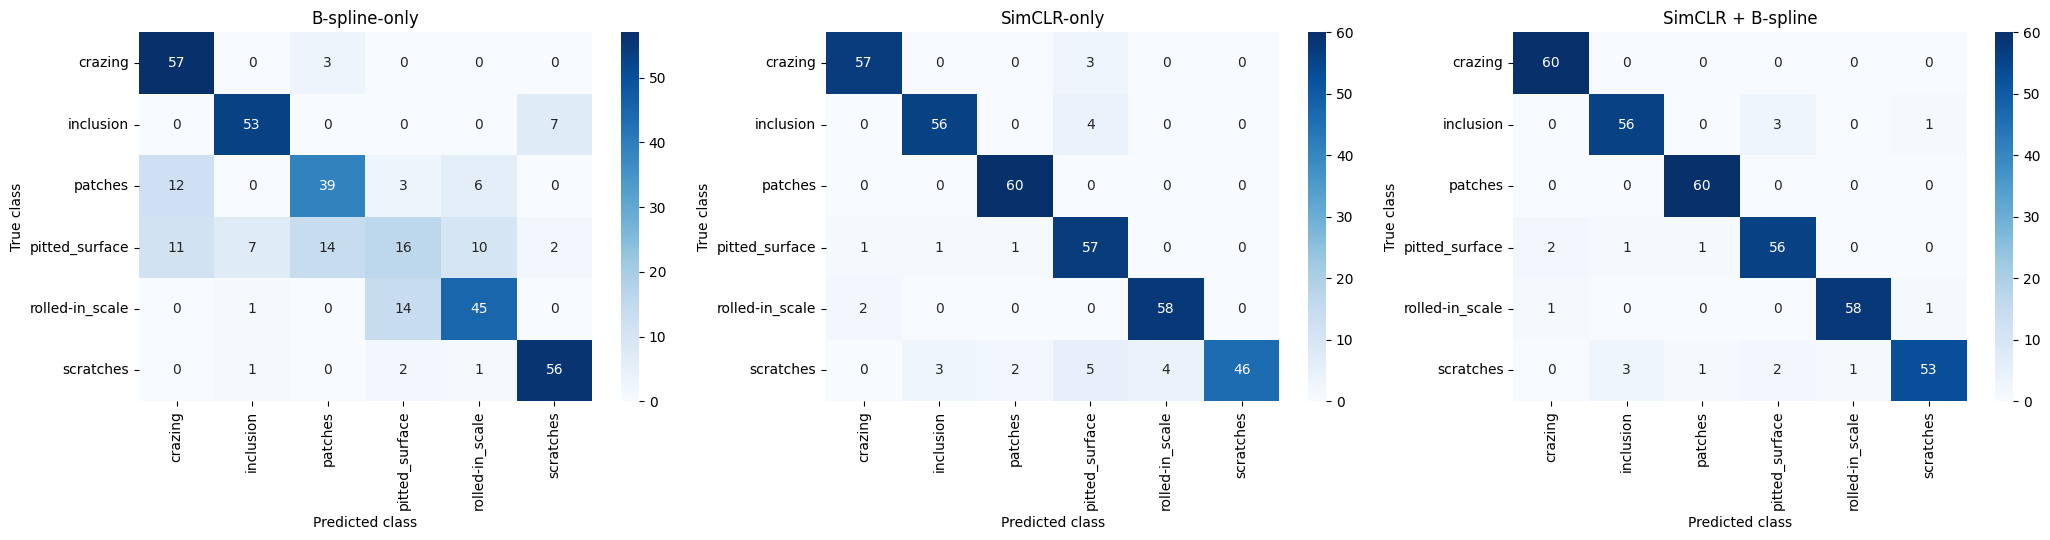

Saved: /content/drive/MyDrive/METALYX/fair_comparison_results/comparison_confusion_matrices.png


In [13]:
fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
for ax, method_name in zip(axes, feature_sets.keys()):
    sns.heatmap(
        confusion_matrices[method_name],
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=CLASS_NAMES,
        yticklabels=CLASS_NAMES,
        ax=ax
    )
    ax.set_title(method_name)
    ax.set_xlabel('Predicted class')
    ax.set_ylabel('True class')
plt.tight_layout()
confusion_plot_path = OUTPUT_DIR / 'comparison_confusion_matrices.png'
plt.savefig(confusion_plot_path, dpi=300, bbox_inches='tight')
plt.show()
print('Saved:', confusion_plot_path)

## 10. Save all results and provenance

This cell saves the summary table, per-class metrics, predictions, exact image paths, extracted features, confusion matrices, and run configuration. Keep these files with the project so the paper's tables can be traced back to the experiment.

In [14]:
# Summary metrics
summary_csv = OUTPUT_DIR / 'feature_fusion_comparison.csv'
results_df.to_csv(summary_csv, index=False)

# Per-class metrics for each method
per_class_rows = []
for method_name, report in reports.items():
    for class_name in CLASS_NAMES:
        per_class_rows.append({
            'method': method_name,
            'class': class_name,
            'precision': report[class_name]['precision'],
            'recall': report[class_name]['recall'],
            'f1_score': report[class_name]['f1-score'],
            'support': report[class_name]['support']
        })
per_class_df = pd.DataFrame(per_class_rows)
per_class_csv = OUTPUT_DIR / 'per_class_metrics.csv'
per_class_df.to_csv(per_class_csv, index=False)

# Predictions and true labels
pred_df = pd.DataFrame({
    'image_path': val_paths,
    'true_label_id': y_val,
    'true_label': [CLASS_NAMES[i] for i in y_val]
})
for method_name, pred in predictions.items():
    safe_name = method_name.lower().replace(' ', '_').replace('+', 'plus').replace('-', '_')
    pred_df[f'{safe_name}_pred_id'] = pred
    pred_df[f'{safe_name}_pred_label'] = [CLASS_NAMES[i] for i in pred]
pred_csv = OUTPUT_DIR / 'validation_predictions.csv'
pred_df.to_csv(pred_csv, index=False)

# Exact split manifest
manifest_df = pd.concat([
    pd.DataFrame({'split': 'train', 'image_path': train_paths,
                  'label_id': y_train, 'label': [CLASS_NAMES[i] for i in y_train]}),
    pd.DataFrame({'split': 'validation', 'image_path': val_paths,
                  'label_id': y_val, 'label': [CLASS_NAMES[i] for i in y_val]})
], ignore_index=True)
manifest_csv = OUTPUT_DIR / 'official_split_manifest.csv'
manifest_df.to_csv(manifest_csv, index=False)

# Save numeric features, paths, labels, and confusion matrices
features_npz = OUTPUT_DIR / 'comparison_features_and_predictions.npz'
np.savez_compressed(
    features_npz,
    train_paths=train_paths, y_train=y_train,
    validation_paths=val_paths, y_validation=y_val,
    X_train_bspline=X_train_bspline, X_val_bspline=X_val_bspline,
    X_train_simclr=X_train_simclr, X_val_simclr=X_val_simclr,
    X_train_fusion=X_train_fusion, X_val_fusion=X_val_fusion,
    pred_bspline=predictions['B-spline-only'],
    pred_simclr=predictions['SimCLR-only'],
    pred_fusion=predictions['SimCLR + B-spline'],
    cm_bspline=confusion_matrices['B-spline-only'],
    cm_simclr=confusion_matrices['SimCLR-only'],
    cm_fusion=confusion_matrices['SimCLR + B-spline'],
    class_names=np.asarray(CLASS_NAMES)
)

run_config = {
    'project': 'METALYX',
    'protocol': 'official NEU-DET train directory for classifier fitting; official validation directory for evaluation',
    'train_count': int(len(train_paths)),
    'validation_count': int(len(val_paths)),
    'class_names': CLASS_NAMES,
    'seed': SEED,
    'checkpoint_path': str(CHECKPOINT_PATH),
    'checkpoint_epoch': checkpoint.get('epoch', None) if isinstance(checkpoint, dict) else None,
    'simclr_encoder': 'ResNet-18; 512-dimensional encoder output',
    'simclr_eval_transform': 'Resize(224,224) + ToTensor(); no ImageNet mean/std normalization',
    'bspline_features': FEATURE_NAMES,
    'bspline_use_clahe': USE_CLAHE,
    'classifier': 'StandardScaler + LogisticRegression',
    'classifier_kwargs': CLASSIFIER_KWARGS,
    'device': str(DEVICE),
    'torch_version': torch.__version__,
    'opencv_version': cv2.__version__,
    'train_zero_bspline_rows': int(train_zero_bspline),
    'validation_zero_bspline_rows': int(val_zero_bspline),
    'note': 'Validation results are not an independent external test result. Verify checkpoint training provenance before publication.'
}
config_path = OUTPUT_DIR / 'run_configuration.json'
with open(config_path, 'w') as f:
    json.dump(run_config, f, indent=2)

print('Saved outputs:')
for p in [summary_csv, per_class_csv, pred_csv, manifest_csv, features_npz, config_path, confusion_plot_path]:
    print('-', p)

Saved outputs:
- /content/drive/MyDrive/METALYX/fair_comparison_results/feature_fusion_comparison.csv
- /content/drive/MyDrive/METALYX/fair_comparison_results/per_class_metrics.csv
- /content/drive/MyDrive/METALYX/fair_comparison_results/validation_predictions.csv
- /content/drive/MyDrive/METALYX/fair_comparison_results/official_split_manifest.csv
- /content/drive/MyDrive/METALYX/fair_comparison_results/comparison_features_and_predictions.npz
- /content/drive/MyDrive/METALYX/fair_comparison_results/run_configuration.json
- /content/drive/MyDrive/METALYX/fair_comparison_results/comparison_confusion_matrices.png


## 11. Reporting template for the project diary / paper

After running the notebook, copy the values from `feature_fusion_comparison.csv` into the table below. Report the result produced by this corrected run—not the earlier 86.11% / 92.50% values unless they are reproduced under this exact protocol.

| Method | Feature dimensions | Validation accuracy | Macro-F1 | Weighted-F1 |
|---|---:|---:|---:|---:|
| B-spline-only | 10 | From output | From output | From output |
| SimCLR-only | 512 | From output | From output | From output |
| SimCLR + B-spline | 522 | From output | From output | From output |

### Suggested cautious interpretation

> Under a common official NEU-DET training/validation protocol, we compared B-spline geometric descriptors, SimCLR encoder features, and their concatenation using the same standardized Logistic Regression classifier. We report validation accuracy, macro-F1, weighted-F1, and class-wise confusion matrices. The fusion approach is considered beneficial only if it improves the relevant metrics over SimCLR-only on the same validation images. These results characterize performance on the official validation set and do not by themselves establish performance on an independent test dataset.

### Before presenting the results

- [ ] Run all cells from top to bottom in one fresh runtime.
- [ ] Confirm strict checkpoint loading succeeds.
- [ ] Confirm the checkpoint was trained without official validation images.
- [ ] Confirm all three methods use the exact same train/validation paths.
- [ ] Save the generated CSV files, split manifest, plots, and checkpoint provenance.
- [ ] Do not call the official validation set an independent test set.
- [ ] If the validation set was used repeatedly for model selection, disclose that limitation and seek a separate test set or repeated cross-validation for stronger evidence.